# Évaluation de l'assistant sur le jeu de test annoté

Ce notebook analyse les résultats de `scripts/evaluate_rag.py` sur les 20 questions du jeu de test. Il relit les fichiers enregistrés dans `data/eval/` : **aucun appel à Mistral**, l'exécution prend quelques secondes.

Trois niveaux de jugement, qui se contrôlent mutuellement :
- un **classement humain** des 20 réponses (correcte / partielle / incorrecte), fait à l'aveugle : c'est la référence ;
- des **mesures exactes**, calculées par le code sans LLM : comportement attendu, événements trouvés par la recherche, événements cités ;
- un **juge LLM** (Ragas, Ministral 14B) : fidélité, pertinence, couverture documentaire, exactitude factuelle.

Plan :
1. Le jeu de test
2. L'assistant répond-il bien ? (classement humain)
3. D'où viennent les erreurs ? (recherche ou génération)
4. Peut-on se fier aux mesures automatiques ? (comparaison avec le classement humain)
5. Une amélioration mesurée : chercher sans le lieu ni la période
6. Conclusions, limites et pistes

## Chargement des résultats

Cette cellule :
- relit les quatre fichiers de `data/eval/` : le jeu de test (`test_set.json`), les réponses de l'assistant (`rag_answers.json`), les mesures et le détail du juge (`rag_evaluation.json`), le classement humain (`manual_judgments.json`) ;
- vérifie que le classement humain porte bien sur ces réponses-là (même date d'obtention) : si les réponses avaient été régénérées, la comparaison n'aurait plus de sens ;
- rassemble tout dans un tableau `table`, une ligne par question : catégorie, verdict et motif humains, comportement, mesures de la recherche, citations, similarité, scores Ragas ;
- fixe le style des graphiques : fond clair, grille discrète, et pour chaque verdict une couleur **et** une forme (vert ● correcte, jaune ■ partielle, rouge ▲ incorrecte), pour que le sens ne repose pas sur la couleur seule.

In [1]:
import json
import sys
from pathlib import Path

# Le notebook s'exécute depuis notebooks/ : on ajoute la racine du projet au chemin d'import.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from rag import config
from rag.evaluation import RAGAS_METRICS, agreement_with_humans, summarize

pd.set_option("display.max_colwidth", 90)


def load(name: str) -> dict:
    return json.loads((config.EVAL_DIR / name).read_text(encoding="utf-8"))


test_set = load("test_set.json")
answers = load("rag_answers.json")
evaluation = load("rag_evaluation.json")
human = load("manual_judgments.json")
assert human["metadata"]["answers_started_at"] == answers["metadata"]["started_at"], \
    "le classement humain porte sur d'autres réponses"

METRIC_LABELS = {"faithfulness": "fidélité", "answer_relevancy": "pertinence",
                 "context_recall": "couverture documentaire", "factual_correctness": "exactitude factuelle"}
VERDICT_LABELS = {"C": "correcte", "P": "partielle", "I": "incorrecte"}

# Une ligne par question : jeu de test, réponse, mesures, classement humain
rows = []
for question in test_set["questions"]:
    key = str(question["id"])
    result, answer = evaluation["questions"][key], answers["answers"][key]
    retrieval, citations, ragas = result["retrieval"] or {}, result["citations"] or {}, result["ragas"] or {}
    rows.append({
        "n°": question["id"], "question": question["question"], "catégorie": question["category"],
        "verdict": human["judgments"][key]["verdict"], "motif": human["judgments"][key]["reason"],
        "comportement": "conforme" if result["behavior_ok"] else "écart",
        "trouvé": retrieval.get("hit"), "rang": retrieval.get("first_rank"),
        "précision": retrieval.get("precision"), "rappel": retrieval.get("recall"),
        "cités pertinents": f"{citations['cited_relevant']}/{citations['cited']}" if citations else None,
        "similarité": result["similarity"],
        **{METRIC_LABELS[metric]: ragas.get(metric) for metric in RAGAS_METRICS},
    })
table = pd.DataFrame(rows).set_index("n°")
print(f"Réponses : {answers['metadata']['model']}, obtenues le {answers['metadata']['started_at'][:10]} ; "
      f"juge Ragas : {evaluation['metadata']['judge_model']} ; date du jour fixée : {test_set['metadata']['today']}")

# Style des graphiques : surface claire, encre sombre, grille discrète ; couleurs d'état (verdicts)
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
VERDICT_COLORS = {"C": "#0ca30c", "P": "#fab219", "I": "#d03b3b"}    # bon / attention / critique
VERDICT_MARKERS = {"C": "o", "P": "s", "I": "^"}                    # forme : le sens ne repose pas sur la couleur
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": AXIS,
                     "axes.labelcolor": INK_2, "xtick.color": MUTED, "ytick.color": INK_2, "text.color": INK,
                     "font.size": 10})

Réponses : ministral-8b-2512, obtenues le 2026-11-20 ; juge Ragas : ministral-14b-2512 ; date du jour fixée : 2026-10-29


## 1. Le jeu de test

20 questions, rédigées comme par un utilisateur, sur la photo de référence (date du jour fixée au 29/10/2026) :
- **14 questions auxquelles les données répondent** (genres, villes et périodes variés, 9 départements sur 12, 10 avec la question sur le passé) ;
- **6 cas limites** : aucun résultat (message fixe attendu), genre absent, hors sujet, autre région, événements passés, question vague.

Pour chaque question, la **référence** est rédigée à partir des données, et la liste des **événements qui répondent à la question** (`relevant_uids`) est établie en cherchant directement dans les données, sans le RAG ; les candidats écartés sont gardés avec leur motif. `tests/test_eval_test_set.py` vérifie que chaque événement retenu existe, respecte le lieu et la période de la question, et qu'une question « sans résultat » ne trouve vraiment aucun événement.

La référence a donc **deux niveaux** : un texte qui donne des exemples, et la liste complète des événements acceptés. Les mesures exactes utilisent la liste ; Ragas ne voit que le texte (voir la partie 4).

In [2]:
CATEGORY_LABELS = {"answer": "à réponse", "no_result": "sans résultat", "absent_genre": "genre absent",
                   "off_topic": "hors sujet", "other_region": "autre région", "past": "passé", "vague": "vague"}
overview = pd.DataFrame([{
    "n°": question["id"], "question": question["question"],
    "catégorie": CATEGORY_LABELS[question["category"]],
    "comportement attendu": question["expected_behavior"],
    "événements acceptés": "tous ceux de la période" if question["relevant_uids"] is None
                           else len(question["relevant_uids"]),
} for question in test_set["questions"]]).set_index("n°")
display(overview["catégorie"].value_counts().rename("questions").to_frame())
overview

,questions
catégorie,
à réponse,14
sans résultat,1
genre absent,1
hors sujet,1
autre région,1
passé,1
vague,1


,question,catégorie,comportement attendu,événements acceptés
n°,,,,
1,Des concerts de jazz à Limoges en novembre ?,à réponse,recommend,27
2,Une exposition à voir à La Rochelle,à réponse,recommend,4
3,Un spectacle d'humour à Bordeaux la semaine prochaine,à réponse,recommend,8
4,Du théâtre à Brive-la-Gaillarde,à réponse,recommend,1
5,Un concert de musique classique à Bordeaux en décembre,à réponse,recommend,7
6,Un film documentaire à Bordeaux,à réponse,recommend,12
7,Un atelier pour enfants à Bordeaux mercredi,à réponse,recommend,12
8,Une exposition gratuite à Bordeaux ce week-end,à réponse,recommend,15
9,Un concert à Aubusson,à réponse,recommend,1


## 2. L'assistant répond-il bien ?

Classement humain des 20 réponses, fait **à l'aveugle** (sans les scores du juge), avec des critères écrits **avant** de lire les réponses ; les faits avancés par les réponses (dates, lieux, tarifs) ont été vérifiés dans les données :
- **C, correcte** : même sens et mêmes informations que la référence (définition de l'énoncé) ; pour un cas limite, comportement attendu respecté ; citer moins d'événements que la référence est permis s'ils répondent bien à la question ;
- **P, partielle** : utile mais imparfaite (un détail faux ou manquant, un événement hors sujet à côté de bons événements, un comportement respecté à moitié) ;
- **I, incorrecte** : n'aide pas ou induit en erreur.

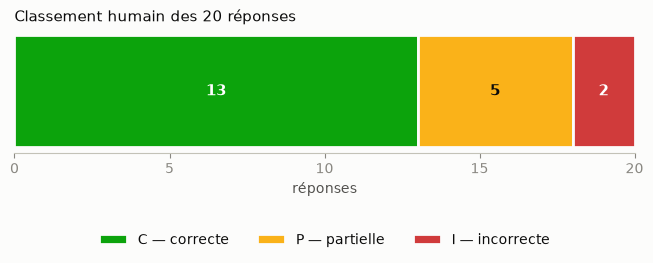

Entièrement correctes : 13/20 ; utiles (correctes ou partielles) : 18/20


,question,verdict,motif
n°,,,
2,Une exposition à voir à La Rochelle,P,"Exposition juste (dates, lieu, entrée libre), mais la phrase « aucun événement ne corr..."
4,Du théâtre à Brive-la-Gaillarde,I,"Ne donne pas l'unique pièce (« Delete », avril 2027) : répond qu'aucun théâtre n'est p..."
5,Un concert de musique classique à Bordeaux en décembre,P,"Deux concerts justes, mais le concert du 2 décembre est présenté à tort comme « en deh..."
6,Un film documentaire à Bordeaux,P,"Deux documentaires justes, mais affirme à tort que les autres ont lieu avant le 29 oct..."
8,Une exposition gratuite à Bordeaux ce week-end,P,"Exposition gratuite acceptée, mais lieu faux : bibliothèque Bordeaux-Lac, et non Jardi..."
11,Que faire à Angoulême en novembre ?,P,"Expositions et apéros justes, mais visite guidée annoncée le « dimanche 2 novembre » (..."
17,Quel temps fera-t-il à Bordeaux ce week-end ?,I,Recommande trois événements alors qu'il devait refuser.


In [3]:
counts = table["verdict"].value_counts().reindex(["C", "P", "I"], fill_value=0)

# Une barre découpée : la part de chaque verdict dans les 20 réponses ; le nombre dans chaque segment,
# le nom du verdict dans la légende (un petit segment ne peut pas contenir un mot)
fig, ax = plt.subplots(figsize=(8, 1.6))
left = 0
for verdict, count in counts.items():
    ax.barh(0, count, left=left, height=0.5, color=VERDICT_COLORS[verdict], edgecolor=SURFACE, linewidth=2,
            label=f"{verdict} — {VERDICT_LABELS[verdict]}")
    ink = INK if verdict == "P" else "#ffffff"   # encre sombre sur le jaune, blanche ailleurs
    ax.text(left + count / 2, 0, str(count), ha="center", va="center", color=ink, fontsize=11, fontweight="bold")
    left += count
ax.set_xlim(0, len(table))
ax.set_xticks(range(0, len(table) + 1, 5))
ax.set_yticks([])
ax.set_xlabel("réponses")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.set_title("Classement humain des 20 réponses", loc="left", color=INK, fontsize=11)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.55), ncol=3, frameon=False)
plt.show()

print(f"Entièrement correctes : {counts['C']}/20 ; utiles (correctes ou partielles) : {counts['C'] + counts['P']}/20")
display(table.loc[table["verdict"] != "C", ["question", "verdict", "motif"]])

**Lecture**
- **13 réponses sur 20 sont entièrement correctes, 18 sur 20 sont utiles.**
- Les 5 réponses partielles contiennent un **détail faux**, et quatre fois sur cinq il porte sur une **date** : un concert du 2 décembre dit « hors période » (Q5), d'autres documentaires dits « avant le 29 octobre » (Q6), une visite annoncée un « dimanche 2 novembre », qui est un lundi (Q11), une phrase fausse sur la date de la demande (Q2). La dernière donne un lieu faux (Q8).
- Les 2 réponses incorrectes : la seule pièce de théâtre de Brive n'est pas proposée (Q4) ; la question sur la météo reçoit trois recommandations au lieu d'un refus (Q17).

## 3. D'où viennent les erreurs ?

La réponse de l'assistant contient la liste des 5 événements **trouvés par la recherche** (transmis au modèle), et pas seulement ceux qu'il **cite**. On peut donc séparer deux causes d'erreur :
- la **recherche** n'a pas trouvé les bons événements ;
- le **modèle** les avait, mais a mal répondu.

Mesures exactes de la recherche, sur les identifiants, pour les 15 questions qui ont des événements attendus :
- **trouvé** : au moins un événement attendu parmi les 5 (Exact Match sur les identifiants) ;
- **rang** du premier événement attendu (sa moyenne de 1 / rang est le MRR) ;
- **précision** : part des 5 événements trouvés qui répondent à la question (le bruit) ;
- **rappel** : part de ce qui pouvait être trouvé (plafonné par les 5 places) ;
- **cités pertinents** : événements cités qui répondent à la question / événements cités.

In [4]:
measured = table[table["trouvé"].notna()]
display(measured[["question", "verdict", "trouvé", "rang", "précision", "rappel", "cités pertinents"]])
summary = summarize(list(evaluation["questions"].values()))
print("Moyennes :", {name: value for name, value in summary["retrieval"].items()},
      "; citations pertinentes :", summary["citations"]["precision"])

,question,verdict,trouvé,rang,précision,rappel,cités pertinents
n°,,,,,,,
1,Des concerts de jazz à Limoges en novembre ?,C,True,2.0,0.8,0.80,4/5
2,Une exposition à voir à La Rochelle,P,True,1.0,0.8,1.00,1/1
3,Un spectacle d'humour à Bordeaux la semaine prochaine,C,True,1.0,0.6,0.60,2/2
4,Du théâtre à Brive-la-Gaillarde,I,False,NaN,0.0,0.00,0/0
5,Un concert de musique classique à Bordeaux en décembre,P,True,1.0,1.0,1.00,3/3
6,Un film documentaire à Bordeaux,P,True,1.0,1.0,1.00,2/2
7,Un atelier pour enfants à Bordeaux mercredi,C,True,1.0,0.8,0.80,4/4
8,Une exposition gratuite à Bordeaux ce week-end,P,True,4.0,0.2,0.20,1/1
9,Un concert à Aubusson,C,True,4.0,0.2,1.00,1/1


Moyennes : {'questions': 15, 'hit_rate': 0.933, 'mrr': 0.8, 'precision': 0.667, 'recall': 0.783} ; citations pertinentes : 0.986


### Question 4 : les événements trouvés par la recherche

Les 5 événements transmis au modèle pour « Du théâtre à Brive-la-Gaillarde », avec leur rang (`ref`), leur score de similarité et une colonne `attendu` : la pièce « Delete », seul événement qui répond à la question, en fait-elle partie ? Si non, l'erreur vient de la recherche, pas du modèle.

In [5]:
# Question 4 : la pièce attendue (« Delete », avril 2027) n'est pas parmi les 5 événements trouvés
expected = test_set["questions"][3]["relevant_uids"]
pd.DataFrame([{**event, "attendu": event["uid"] in expected} for event in answers["answers"]["4"]["retrieved"]])

,ref,uid,title,score,attendu
0,1,58942113,Games Gaillardes n° 92,0.794,False
1,2,59375961,Games Gaillardes n° 93,0.792,False
2,3,25572983,Games Gaillardes n° 94,0.791,False
3,4,40749380,Apéro célibataires — Brive-la-Gaillarde,0.791,False
4,5,9960570,Apéro célibataires — Brive-la-Gaillarde,0.790,False


**Lecture**
- **La recherche trouve un bon événement pour 14 questions sur 15**, en général au premier rang ; les événements cités sont presque toujours pertinents.
- **Une seule erreur vient de la recherche : la question 4.** « Du théâtre à Brive-la-**Gaillarde** » ramène trois « Games **Gaillardes** » et deux apéros : la ressemblance avec le nom de la ville l'emporte sur le genre demandé. Le modèle répond alors honnêtement qu'aucun théâtre ne figure parmi ce qu'il a reçu.
- **Toutes les autres erreurs viennent du modèle** (Ministral 8B) : les dates (Q5, Q6, Q11), un lieu (Q8), une phrase fausse (Q2), un refus non tenu (Q17). Les bons événements étaient trouvés.

## 4. Peut-on se fier aux mesures automatiques ?

On regroupe les réponses selon le verdict humain (C, P, I) et on calcule la moyenne de chaque mesure dans chaque groupe. Une mesure utile donne des valeurs **nettement différentes** d'un groupe à l'autre ; une mesure qui donne la même valeur aux trois groupes ne distingue pas les bonnes réponses des mauvaises.

,C,P,I
questions,13.000,5.000,2.000
écarts signalés par les règles,1.000,0.000,2.000
similarité,0.920,0.912,0.870
jugées par Ragas,9.000,5.000,1.000
fidélité,0.888,0.796,0.000
pertinence,0.828,0.839,0.811
couverture documentaire,0.605,0.632,0.000
exactitude factuelle,0.484,0.386,0.000


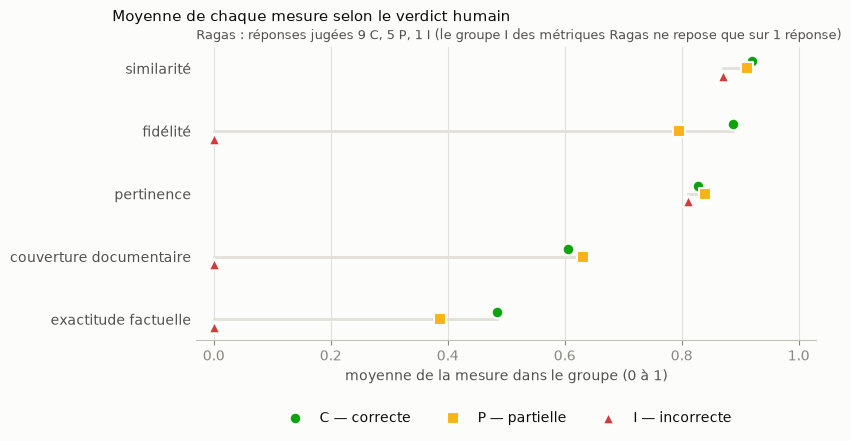

In [6]:
verdicts = {key: judgment["verdict"] for key, judgment in human["judgments"].items()}
agreement = pd.DataFrame(agreement_with_humans(evaluation["questions"], verdicts))
agreement = agreement.rename(index={"behavior_flagged": "écarts signalés par les règles", "questions": "questions",
                                    "similarity": "similarité", "judged": "jugées par Ragas", **METRIC_LABELS})
display(agreement)

# Une ligne par mesure, un point par verdict : des points écartés = la mesure distingue les réponses.
# Léger décalage vertical par verdict : deux valeurs presque égales restent visibles toutes les deux.
measures = ["similarité", *METRIC_LABELS.values()]
OFFSETS = {"C": 0.12, "P": 0.0, "I": -0.12}
fig, ax = plt.subplots(figsize=(8, 3.8))
for row, measure in enumerate(reversed(measures)):
    values = agreement.loc[measure].dropna()
    ax.plot([values.min(), values.max()], [row, row], color=GRID, linewidth=2, zorder=1)
    for verdict, value in values.items():
        ax.scatter(value, row + OFFSETS[verdict], s=70, color=VERDICT_COLORS[verdict],
                   marker=VERDICT_MARKERS[verdict], edgecolor=SURFACE, linewidth=1.5, zorder=2,
                   label=f"{verdict} — {VERDICT_LABELS[verdict]}" if row == 0 else None)
ax.set_yticks(range(len(measures)), list(reversed(measures)))
ax.set_xlim(-0.03, 1.03)
ax.set_xlabel("moyenne de la mesure dans le groupe (0 à 1)")
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
judged = agreement.loc["jugées par Ragas"].astype(int)
fig.suptitle("Moyenne de chaque mesure selon le verdict humain", x=0.02, ha="left", color=INK, fontsize=11)
ax.set_title(f"Ragas : réponses jugées {judged['C']} C, {judged['P']} P, {judged['I']} I "
             f"(le groupe I des métriques Ragas ne repose que sur {judged['I']} réponse)",
             loc="left", color=INK_2, fontsize=9)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
plt.show()

### Le détail de la fidélité, pour les réponses partielles et incorrectes

Pour chaque réponse classée P ou I et jugée par Ragas : l'erreur notée par l'humain, puis les affirmations que le juge a déclarées **non appuyées** par les événements transmis, avec son motif. On peut ainsi voir, réponse par réponse, si le juge a trouvé la même erreur que l'humain, s'il l'a manquée, ou s'il a signalé autre chose.

In [7]:
# Fidélité : affirmations que le juge a déclarées non appuyées, pour les réponses classées P ou I
for key, judgment in human["judgments"].items():
    scores = evaluation["questions"][key]["ragas"]
    if judgment["verdict"] == "C" or not scores:
        continue
    rejected = [item for item in scores["faithfulness_statements"] if not item["verdict"]]
    text = [f"### Question {key} ({judgment['verdict']}) — erreur notée par l'humain : {judgment['reason']}",
            f"Fidélité : {scores['faithfulness']:.2f} ; affirmations jugées non appuyées :"]
    text += [f"- « {item['statement']} » : {item['reason']}" for item in rejected] or ["- aucune"]
    display(Markdown("\n".join(text)))

### Question 2 (P) — erreur notée par l'humain : Exposition juste (dates, lieu, entrée libre), mais la phrase « aucun événement ne correspond pour le 29 octobre » est fausse : la question ne donnait pas de date et d'autres expositions existent.
Fidélité : 0.71 ; affirmations jugées non appuyées :
- « The exhibition "Le H de Atlantique" will run from November 1, 2026, to November 8, 2026. » : The context states the exhibition runs from September 12, 2026, to November 8, 2026, not starting on November 1, 2026.
- « The user could broaden the search to the following week to find more available options. » : The context does not provide any guidance or suggestion for broadening the search period; this is an external recommendation not supported by the given context.

### Question 4 (I) — erreur notée par l'humain : Ne donne pas l'unique pièce (« Delete », avril 2027) : répond qu'aucun théâtre n'est proposé.
Fidélité : 0.00 ; affirmations jugées non appuyées :
- « No theatre events are currently available in Brive-la-Gaillarde for upcoming dates starting from October 29, 2026, according to available suggestions. » : The context does not mention theatre events at all, nor does it provide any information about events starting from October 29, 2026. The available events are related to board games and apéros for singles.
- « The information is based on the current database of events. » : The context does not explicitly mention a 'database of events,' but it provides specific details about scheduled events. This statement cannot be directly inferred from the given context.
- « A search for other types of cultural events can be conducted if desired. » : The context does not mention any mechanism or suggestion for conducting searches or exploring other types of cultural events beyond what is listed.
- « Cultural events may include music performances, exhibitions, board games, or other related activities. » : The context explicitly mentions board games (jeux de société) and apéros, but does not mention music performances or exhibitions. The statement partially aligns but is not fully supported by the context.
- « An alternative time period can be selected for event searches. » : The context does not provide any information about the possibility of selecting alternative time periods for event searches.
- « Assistance is available to explore additional options for events. » : The context mentions animators are present to help discover and learn about games, but it does not explicitly state that assistance is available for exploring additional event options beyond the listed ones.

### Question 5 (P) — erreur notée par l'humain : Deux concerts justes, mais le concert du 2 décembre est présenté à tort comme « en dehors de votre période ».
Fidélité : 0.92 ; affirmations jugées non appuyées :
- « Les deux premiers concerts mentionnés correspondent à la période de décembre 2026 demandée. » : Les deux premiers concerts (Concert de Noël Radio Classique et Les Quatre Saisons de Vivaldi) ont lieu respectivement du 17 au 20 décembre et le 27 décembre 2026, mais le second ne correspond pas entièrement à la période demandée (du 17 au 20 décembre).

### Question 6 (P) — erreur notée par l'humain : Deux documentaires justes, mais affirme à tort que les autres ont lieu avant le 29 octobre.
Fidélité : 0.75 ; affirmations jugées non appuyées :
- « Two documentary films are proposed in Bordeaux starting from October 29, 2026. » : The context mentions multiple documentary events starting from October 29, 2026, including projections and debates, but does not explicitly state that only two films are proposed. The phrase 'starting from' is ambiguous and could imply more events beyond the listed ones.
- « Other documentary films in Bordeaux have screening dates prior to October 29, 2026. » : The context does not mention any documentary films with screening dates before October 29, 2026. All listed events start on or after that date.

### Question 8 (P) — erreur notée par l'humain : Exposition gratuite acceptée, mais lieu faux : bibliothèque Bordeaux-Lac, et non Jardin botanique Bastide.
Fidélité : 0.90 ; affirmations jugées non appuyées :
- « The location of the exhibition is the Jardin botanique Bastide. » : The exhibition 'Mine d'Emile s'expose' is located at Bibliothèque Bordeaux-Lac, not the Jardin botanique Bastide.

### Question 11 (P) — erreur notée par l'humain : Expositions et apéros justes, mais visite guidée annoncée le « dimanche 2 novembre » (un lundi) au lieu du dimanche 1er novembre.
Fidélité : 0.70 ; affirmations jugées non appuyées :
- « L'exposition *sténopé/coconstruction* est accessible pendant toute la période demandée. » : Le contexte indique que l'exposition est accessible du lundi 2 novembre au samedi 21 novembre 2026, mais ne précise pas si elle est accessible *toute la journée* pendant cette période. La formulation 'toute la période demandée' est ambiguë et non explicitement confirmée.
- « Une visite guidée gratuite de l'exposition *Croissant Indigerible / علاقات عرنسية* est organisée le dimanche 2 novembre à 16h. » : Le contexte précise qu'une visite accompagnée gratuite a lieu tous les premiers dimanches du mois à 16h, mais la date mentionnée est le dimanche 1 novembre, non le 2 novembre.
- « Les apéros ont lieu un vendredi, deux mardis et un autre jour non précisé dans la liste fournie. » : Le contexte mentionne un apéro le vendredi 6 novembre et deux apéros les mardis 3 et 10 novembre. Aucune autre date n'est précisée, donc la formulation 'un autre jour non précisé' est incorrecte.

**Lecture**
- **Règles de comportement** : les 2 réponses incorrectes sont signalées. Une fausse alerte : Q19 (concerts passés) est correcte, mais ne dit pas explicitement « terminé » ; la règle est trop stricte. Elle n'a pas été retouchée après coup : ajuster une règle sur les réponses qu'elle juge reviendrait à la régler pour obtenir le résultat voulu. Les détails faux (réponses P) sont invisibles aux règles, comme prévu.
- **Similarité et pertinence ne distinguent rien** : presque la même valeur pour les trois groupes ; la réponse fausse de Q4 a la même similarité que des réponses correctes. Deux textes sur le même sujet ont des vecteurs proches, même si un fait diffère.
- **Couverture documentaire** : elle mesure la recherche, pas la réponse ; elle est basse pour les questions larges (beaucoup d'événements attendus pour 5 places).
- **Exactitude factuelle** : ordonnée (C > P > I) mais faussée par la référence à deux niveaux : une réponse qui cite d'autres événements, tout aussi justes, que les exemples du texte est pénalisée (Q1, correcte : 0,10).
- **Fidélité : la plus utile, à condition de lire son détail.** Elle retrouve l'erreur de 3 réponses partielles sur 5 (Q6, Q8, Q11), en manque 2 (Q2, Q5), et lance de fausses alertes sur des réponses correctes (phrase d'introduction, offre d'élargir la recherche, détail pointilleux). Q4 obtient 0 pour de mauvaises raisons : l'erreur venait de la recherche.

**Conclusion** : aucun score ne suffit seul. Le classement humain reste la référence ; les mesures exactes (comportement, recherche, citations) et la lecture du détail de la fidélité sont les signaux automatiques les plus fiables.

## 5. Une amélioration mesurée : chercher sans le lieu ni la période

La partie 3 a montré une erreur de recherche (Q4) : « Du théâtre à Brive-la-**Gaillarde** » ramène les « Games **Gaillardes** ». Or le lieu et la période **filtrent déjà** les événements : les garder dans le texte vectorisé n'apporte rien et fausse la similarité.

**Changement testé** : la recherche par similarité porte sur la question **sans le lieu ni la période** repérés (« Du théâtre ») ; la question entière sert toujours à repérer les critères et à rédiger la réponse. Un lieu non repéré (« à Toulouse ») reste dans le texte.

**Méthode** : un seul changement ; mêmes 20 questions, même date du jour, même modèle ; nouvelle évaluation dans un dossier séparé (`data/eval/question_reduite/`, `--no-ragas`), la référence restant intacte. Réglage : `config.SEARCH_REDUCED_QUESTION` (vrai désormais ; faux : question entière, pour comparer).

In [8]:
reduced = json.loads((config.EVAL_DIR / "question_reduite" / "rag_evaluation.json").read_text(encoding="utf-8"))
reduced_answers = json.loads((config.EVAL_DIR / "question_reduite" / "rag_answers.json").read_text(encoding="utf-8"))
before, after = summarize(list(evaluation["questions"].values())), summarize(list(reduced["questions"].values()))

comparison = pd.DataFrame({
    "question entière": [f"{before['behavior_ok']}/20", *[before["retrieval"][key] for key in ("hit_rate", "mrr", "precision", "recall")],
                         before["citations"]["precision"], before["similarity"]],
    "question réduite": [f"{after['behavior_ok']}/20", *[after["retrieval"][key] for key in ("hit_rate", "mrr", "precision", "recall")],
                         after["citations"]["precision"], after["similarity"]],
}, index=["comportement attendu", "événement attendu trouvé", "MRR", "précision", "rappel",
          "citations pertinentes", "similarité"])
display(comparison)

# Questions dont la recherche ou le comportement change
rows = []
for question in test_set["questions"]:
    key = str(question["id"])
    old, new = evaluation["questions"][key], reduced["questions"][key]
    rank = lambda result: (result["retrieval"] or {}).get("first_rank")
    if rank(old) != rank(new) or old["behavior_ok"] != new["behavior_ok"]:
        rows.append({"n°": question["id"], "question": question["question"],
                     "texte cherché": reduced_answers["answers"][key]["metadata"]["search_text"],
                     "rang avant": rank(old), "rang après": rank(new),
                     "comportement avant": "conforme" if old["behavior_ok"] else "écart",
                     "comportement après": "conforme" if new["behavior_ok"] else "écart"})
# Entiers acceptant une case vide : Q4 n'avait pas de rang avant (événement attendu non trouvé)
display(pd.DataFrame(rows).astype({"rang avant": "Int64", "rang après": "Int64"}).set_index("n°"))
display(Markdown("**Q4 avec la question réduite**\n\n> " + reduced_answers["answers"]["4"]["answer"][:500].replace("\n", "\n> ")))

,question entière,question réduite
comportement attendu,17/20,19/20
événement attendu trouvé,0.933,1.0
MRR,0.8,0.956
précision,0.667,0.707
rappel,0.783,0.877
citations pertinentes,0.986,0.978
similarité,0.913,0.914


,question,texte cherché,rang avant,rang après,comportement avant,comportement après
n°,,,,,,
1,Des concerts de jazz à Limoges en novembre ?,Des concerts de jazz,2,1,conforme,conforme
4,Du théâtre à Brive-la-Gaillarde,Du théâtre,<NA>,1,écart,conforme
8,Une exposition gratuite à Bordeaux ce week-end,Une exposition gratuite,4,1,conforme,conforme
9,Un concert à Aubusson,Un concert,4,3,conforme,conforme
19,Y a-t-il eu des concerts en Lot-et-Garonne le mois dernier ?,Y a-t-il eu des concerts,1,1,écart,conforme


**Q4 avec la question réduite**

> À Brive-la-Gaillarde, voici l'événement de théâtre disponible à partir du **29 octobre 2026** :
> 
> - **« Delete »** (à partir du **6 avril 2027**) au **L'Empreinte - Théâtre de Brive** : une pièce mêlant théâtre et réflexion sur les intelligences artificielles, la mémoire et l'identité, portée par Anne Théron [1].
> *Attention : cet événement n'est pas encore programmé pour la période demandée (à partir du 29 octobre 2026).*
> 
> Aucun autre événement théâtral n'est prévu à Brive-la-Gaillarde dans les s

**Lecture**
- **Toutes les mesures de la recherche s'améliorent** : un bon événement trouvé 15 fois sur 15 (au lieu de 14), le premier bon événement presque toujours au premier rang (MRR 0,96), plus de pertinents parmi les 5 (précision, rappel).
- **Q4 est corrigée** : « Delete » est trouvée au premier rang et proposée. La réponse ajoute encore une remarque confuse sur la période : la faiblesse du modèle sur les dates demeure (génération, pas recherche).
- **Q8** cite deux expositions gratuites, au bon lieu ; **Q19** présente les concerts comme passés.
- **Q17 (météo) reste en écart** : le refus non tenu vient du prompt, pas de la recherche.
- La similarité ne bouge pas (0,91) : elle ne distinguait déjà pas les bonnes réponses des mauvaises.

**Décision** : changement adopté (`search_text` dans `rag/criteria.py`, `SEARCH_REDUCED_QUESTION = True`). La boucle est complète : évaluer → trouver la cause → changer une seule chose → re-mesurer sur le même jeu de test.

## 6. Conclusions, limites et pistes

**Ce que montre l'évaluation**
- 13 réponses sur 20 entièrement correctes, 18 sur 20 utiles ; la recherche trouve un bon événement 14 fois sur 15.
- Les erreurs viennent surtout du **modèle**, et d'abord des **dates** ; une erreur vient de la **recherche** (nom de ville).
- **Chercher sans le lieu ni la période** (partie 5) corrige l'erreur de recherche : un bon événement trouvé 15 fois sur 15, MRR 0,80 → 0,96, comportement attendu 17 → 19 sur 20 ; adopté dans `rag/criteria.py` (`search_text`).

**Limites**
- **20 questions** : chaque question pèse 5 % ; les écarts de quelques points ne sont pas significatifs.
- **Les nouvelles réponses (partie 5) n'ont pas été classées par un humain** : leur jugement repose sur les mesures exactes et la lecture de Q4, Q8 et Q19.
- **Un seul juge**, et petit (Ministral 14B, imposé par la formule gratuite de Mistral) : ses verdicts se contredisent parfois.
- **Référence à deux niveaux** : l'exactitude factuelle de Ragas ne voit que les exemples du texte.
- **Règle du « passé » trop stricte** (fausse alerte Q19), gardée telle quelle.
- **Couverture des données** : l'offre dépend des organisateurs qui publient sur Open Agenda (Gironde surreprésentée) et de la date de la photo (événements lointains encore peu publiés).
- **Dépendance à l'API de Mistral** : 2 requêtes par minute avec la formule gratuite, évaluation complète en plus d'une heure.

**Pistes, à mesurer avec ce même jeu de test**
- **Recherche** : recherche hybride (mots-clés + vecteurs), à comparer à la recherche actuelle avec ce même jeu de test.
- **Dates** : donner au modèle les dates déjà comparées par le code (essayé dans le notebook 04, B7.7 : les remarques fausses sur les dates disparaissent, mais pas le faux négatif du théâtre à Poitiers ; à mesurer sur Q2, Q5, Q6 et Q11), ou un modèle plus fort (Mistral Large 4, avec une offre payante).
- **Refus** : renforcer la règle hors sujet du prompt (Q17).
- **Automatisation** : `--no-ragas` donne les mesures sans juge en ≈ 10 min, réponses comprises (moins d'une minute avec `--phase judge --no-ragas` sur des réponses enregistrées) ; dans l'intégration continue, il faudrait confier une clé Mistral à GitHub (secret), car les réponses et la similarité appellent Mistral.